# Cleveland Dot Plot

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Dots on a common scale, one row per category, sorted by value. Without bars the axis need not start at zero, so small differences between similar values become visible.

## When to use

- Rank values that are close together and far from zero (e.g. life expectancy 70–85)
- Compare two values per category (before/after, men/women) on each row

## Avoid when

- Readers will judge proportions from position (start at zero or use bars)

## Alternatives

- Dumbbell chart
- Lollipop chart

## Design tips

- Use light horizontal guide lines to link each dot to its label
- When showing two dots per row, sort by one of them or by their difference

## Example

Life expectancy for women and men in 12 countries (synthetic), sorted by women's value.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
countries = ["Japan", "Spain", "Korea", "Italy", "France", "Canada", "UK", "Germany",
             "Chile", "USA", "China", "Brazil"]
women = [87.6, 86.2, 86.5, 85.6, 85.7, 84.5, 83.0, 83.4, 82.5, 80.2, 80.5, 79.4]
men = [81.6, 80.9, 80.3, 81.2, 79.7, 80.5, 79.4, 78.6, 77.3, 74.8, 75.2, 72.8]
df = pd.DataFrame({"country": countries, "women": women, "men": men})
df = df.sort_values("women").reset_index(drop=True)
df.tail()

,country,women,men
7,Italy,85.6,81.2
8,France,85.7,79.7
9,Spain,86.2,80.9
10,Korea,86.5,80.3
11,Japan,87.6,81.6


### Plot

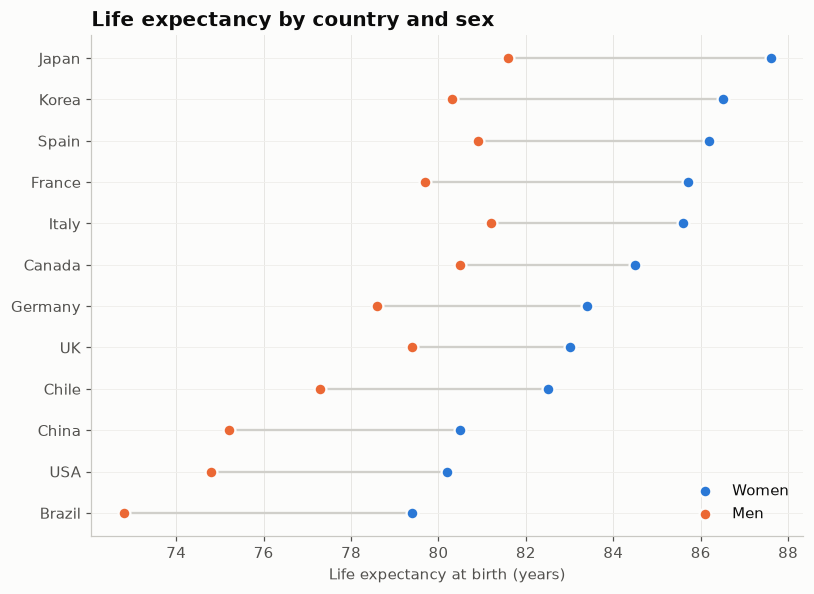

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.hlines(df.index, df["men"], df["women"], color="#d0cfca", linewidth=1.5, zorder=1)
ax.scatter(df["women"], df.index, s=60, color=PALETTE[0], label="Women", zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(df["men"], df.index, s=60, color=PALETTE[1], label="Men", zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5)
ax.set_yticks(df.index, df["country"])
ax.set_xlabel("Life expectancy at birth (years)")
ax.set_title("Life expectancy by country and sex")
ax.legend(loc="lower right")
ax.grid(axis="y", color="#efeeeb")
fig.tight_layout()
plt.show()

## How to read it

Each row is a country. Blue dots are women and orange dots men, and the gray line is the gap. Women outlive men everywhere; the gap is widest in Brazil (6.6 years) and Korea (6.2) and narrowest in the UK (3.6).

---
Standalone script: [`cleveland_dot.py`](cleveland_dot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)